# Quickstart: geodesics, logarithms, compression and statistics on St(n, p)

This notebook runs on a CPU in well under a minute. Except in the cells that name another metric, it uses the
canonical metric (`alpha = 0`). Each printed number below comes from the cell that prints it.

In [1]:
import time

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

jax.config.update("jax_enable_x64", True)  # the library computes in the dtype of its inputs
import stiefel as sf  # noqa: E402

key = jax.random.key(0)
print(jax.__version__, sf.__version__, jax.devices())

0.12.0.1 0.1.0 [CpuDevice(id=0)]


## A geodesic between two frames

We draw a frame `x` of St(200, 4) and a tangent vector `d` of canonical length 1.3. Then we form the endpoint
`y = exp(x, d)`. From `x` and `y`, the logarithm recovers `d`. Along the geodesic `t -> exp(x, t D)`, the
Riemannian speed must equal the length of `D` at every `t`. Since `exp` is differentiable in forward and in
reverse mode, we compute the velocity with `jax.jvp`. This holds at `t = 0` too, where the tangent vector is
zero.

In [2]:
kx, kd, key = jax.random.split(key, 3)
x = sf.random_point(kx, 200, 4)
d = sf.random_tangent(kd, x)
d = 1.3 * d / sf.norm(x, d)
y = sf.exp(x, d)

res = sf.log(x, y)
print(f"converged: {bool(res.converged)}, iterations: {int(res.iterations)}")
print(f"residual: {float(res.residual):.1e}")
print("max |log(x, y) - d| =", float(jnp.max(jnp.abs(res.tangent - d))))


def speed(t):
    point, velocity = jax.jvp(lambda s: sf.exp(x, s * res.tangent), (t,), (1.0,))
    return sf.norm(point, velocity)


ts = jnp.linspace(0.0, 1.0, 11)
speeds = jax.vmap(speed)(ts)
print("speed along the geodesic: min", float(speeds.min()), " max", float(speeds.max()))
print("distance(x, y) =", float(sf.distance(x, y)))

converged: True, iterations: 4
residual: 9.5e-14
max |log(x, y) - d| = 1.426636586643326e-14


speed along the geodesic: min 1.2999999999999996  max 1.3
distance(x, y) = 1.3


## The status of a logarithm

`log` always returns a `LogResult`, with the fields `tangent`, `residual`, `iterations` and `converged`. Here
`residual` is the Frobenius norm of `exp(base, tangent) - point`. For a near pair, the iteration converges in
a few steps. Next, we take a pair whose first columns are opposite (`point[:, 0] = -base[:, 0]`). Such a point
lies on the cut locus, where the algorithm has no real principal matrix logarithm to work with. `log` then
returns `converged = False`, and `distance` returns NaN instead of a number.

In [3]:
near = sf.exp(x, 0.2 * d)
far = x.at[:, 0].multiply(-1.0)
for name, point in [("near", near), ("far", far)]:
    r = sf.log(x, point)
    print(
        f"{name:4s}: converged={bool(r.converged)!s:5s} iterations={int(r.iterations):3d} "
        f"residual={float(r.residual):.2e} distance={float(sf.distance(x, point)):.4f}"
    )

near: converged=True  iterations=  2 residual=8.01e-16 distance=0.2600
far : converged=False iterations=  0 residual=2.00e+00 distance=nan


## Exact compression of 50 frames of size 20000 x 5

`joint_basis` computes an orthonormal basis `W` of the span of all columns, here with `K = 250`. It also
computes the small frames `Y_i` with `X_i = W Y_i`. The map `Y -> W Y` is an isometric embedding of St(K, p)
in St(n, p), and it commutes with `exp` and `log`. Every distance can therefore be computed on the 250 x 5
frames, and `pairwise_distance` does this internally. For the comparison, we time the ambient logarithms on a
subset of 8 frames (28 pairs), and then we scale the time per pair.

In [4]:
n, p, M = 20_000, 5, 50
frames = jax.vmap(lambda k: sf.random_point(k, n, p))(jax.random.split(jax.random.key(1), M))

t0 = time.perf_counter()
jb = sf.joint_basis(frames)
jb.basis.block_until_ready()
print("basis", jb.basis.shape, "coordinates", jb.coordinates.shape)
print(f"joint_basis: {time.perf_counter() - t0:.2f} s")

sf.pairwise_distance(frames[:3]).block_until_ready()  # compile once
t0 = time.perf_counter()
dist_all = sf.pairwise_distance(frames).block_until_ready()
t_comp = time.perf_counter() - t0
pairs = M * (M - 1) // 2
# The compressed time includes the joint_basis call inside pairwise_distance.
print(f"compressed: {pairs} pairs in {t_comp:.2f} s, {1e3 * t_comp / pairs:.2f} ms per pair")

m = 8
i, j = np.triu_indices(m, 1)
ambient = jax.jit(jax.vmap(sf.distance))
ambient(frames[i], frames[j]).block_until_ready()  # compile once
t0 = time.perf_counter()
dist_sub = ambient(frames[i], frames[j]).block_until_ready()
t_amb = time.perf_counter() - t0
print(f"ambient: {len(i)} pairs in {t_amb:.2f} s, {1e3 * t_amb / len(i):.2f} ms per pair")
print("max difference on the subset:", float(jnp.max(jnp.abs(dist_sub - dist_all[i, j]))))

basis (20000, 250) coordinates (50, 250, 5)
joint_basis: 0.75 s


compressed: 1225 pairs in 2.00 s, 1.63 ms per pair


ambient: 28 pairs in 0.14 s, 5.04 ms per pair
max difference on the subset: 4.884981308350689e-15


## Fréchet mean and k-means of two clusters

We place two centres at canonical distance 1.5 on St(60, 3). Around each of them, we draw 20 frames at
distance 0.3 from the centre. `frechet_mean` runs the fixed-point iteration `X <- exp(X, mean of log(X,
points))`, which finds a stationary point of the sum of squared distances. Only if the points lie in a small
enough geodesic ball is this point the unique mean. Starting from a k-means++ draw, `kmeans` alternates
assignments and Fréchet means.

In [5]:
kc, kt, ks, key = jax.random.split(key, 4)
c0 = sf.random_point(kc, 60, 3)
t = sf.random_tangent(kt, c0)
c1 = sf.exp(c0, 1.5 * t / sf.norm(c0, t))


def cloud(centre, k, size=20, radius=0.3):
    def one(kk):
        v = sf.random_tangent(kk, centre)
        return sf.exp(centre, radius * v / sf.norm(centre, v))

    return jax.vmap(one)(jax.random.split(k, size))


k0, k1 = jax.random.split(ks)
points = jnp.concatenate([cloud(c0, k0), cloud(c1, k1)])
truth = np.repeat([0, 1], 20)

mean0 = sf.frechet_mean(points[:20])
print(f"Frechet mean of cluster 0: converged {bool(mean0.converged)}, iterations {int(mean0.iterations)}")
print(
    f"gradient norm {float(mean0.gradient_norm):.1e}, distance to c0 {float(sf.distance(mean0.mean, c0)):.3f}"
)

km = sf.kmeans(jax.random.key(2), points, 2, n_init=3)
labels = np.asarray(km.labels)
agree = max(np.mean(labels == truth), np.mean(labels != truth))
print(f"k-means: converged {bool(km.converged)}, iterations {int(km.iterations)}")
print(f"inertia {float(km.inertia):.3f}")
print(f"agreement with the true clusters: {agree:.0%}")

Frechet mean of cluster 0: converged True, iterations 4


gradient norm 1.0e-11, distance to c0 0.065


k-means: converged True, iterations 2
inertia 3.431
agreement with the true clusters: 100%


## A picture: classical multidimensional scaling of the distance matrix

We add the two k-means centres to the 40 frames, and we compute all geodesic distances. Then the points are
embedded in the plane by classical multidimensional scaling. This method double-centres the squared
distances and takes the top two eigenvectors.

all distances finite: True


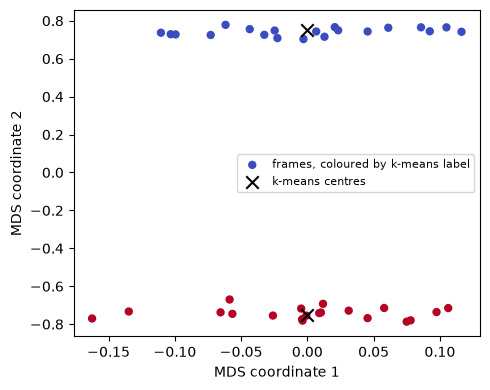

In [6]:
allpts = jnp.concatenate([points, km.centers])
D = np.asarray(sf.pairwise_distance(allpts))
print("all distances finite:", bool(np.isfinite(D).all()))

J = np.eye(len(D)) - 1.0 / len(D)
w, v = np.linalg.eigh(-0.5 * J @ (D**2) @ J)
xy = v[:, -2:] * np.sqrt(w[-2:])

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(*xy[:40].T, c=labels, cmap="coolwarm", s=25, label="frames, coloured by k-means label")
ax.scatter(*xy[40:].T, marker="x", c="k", s=80, label="k-means centres")
ax.set_xlabel("MDS coordinate 1")
ax.set_ylabel("MDS coordinate 2")
ax.legend(loc="best", fontsize=8)
fig.tight_layout()

## What to read next

Every function is listed in the README with its cost. The README also gives the measured domain of the
logarithm for each metric, and it describes the interoperability with pymanopt and geomstats. You can find the
contracts of the functions in their docstrings, and the invariants that they cite are in `INVARIANTS.md`.